# pandaICT datamodel

The pandaICT core datamodel is comprised of the elements according to following table. 

| **Element** | **Description** |
| --- | --- |
| **Node**   | Physical network distributor or interconnection point. May connect networks of different **Link types**. |
| **Device** | Physical end-to-end device, e.g. server, meter, controller hardware etc.  | 
| **Link**   | Physical interconnection between **Device**s and **Node**s or in-between **Node**s. | 
| **App**    | Logical application-level service that is communicating over the network. Associated to exactly one Device the App is "running" on. | 
| **Conn**   | Logical end-to-end interconnection between **App**s. Using a specified protocol to transmit **InfoItem**s | 

The core furthermore contains several definitions for standard elements or element types that are either implemented as std_type structures or simply as aenums (i.e. enumeration type that can be extended at runtime):

| **std_type** | **implementation** | **Description** |
| --- | --- | --- |
| **linktypes**     | std_type | Standard types for links, e.g. LAN1000, LTE50, RS485 etc. |
| **protocoltypes** | std_type | Standard types for protocols, e.g. TCP, FTP, HTTP  | 
| **NodeType**      | aenum    | Standard node types, e.g. SWITCH, ROUTER | 
| **DeviceType**    | aenum    | Standard device types, e.g. RTU, SERVER |
| **AppType**       | aenum    | Standard app types, e.g. WEBSERVER | 
| **InfoItem**      | aenum    | Information Item standard type, e.g. ACK, REQUEST, FILE etc. | 

Note that **connectors** may add application-specific standard types implemented either way. E.g. the **pp_pict_connector** adds IEC61850-MMS to the protocoltypes and ELECTRIC_METER_VALUE to the **InfoItem** aenum. 

The following sections contain a more detailed explanation of the elements.
(NOTE: **bold** text in the following description indicates elements of the data model.)


## Physical model

The physical network model represents ISO/OSI layers 1-3 and includes **Node**s, **Device**s and **Link**s. 

### Nodes

A **Node** is a basic physical network interconnection point for point-to-point **Link**s. It supports one or more **linktypes** that can be connected to it. If more than one **linktype** is supported, it is assumed that the node can translate messages between them; however, it can *not* translate protocols. Also, nodes can typically route messages, which may traverse through the network on different paths defined by **Nodes** and **Links**. Geodata may be applied to a **Node**. 

### Devices

A **Device** is a physical communication endpoint connected to one or more **Links**. By these links, a device is usually connected to one or more **Node**s. Direct connection to other devices ("Ad-hoc-connection") is *not* possible. If such a connection is to be modelled, a dummy **Node** should be placed in between the devices.

### Links
**Link**s represent physical point-to-point connections at ISO/OSI layers 1 and 2. A single link may be uni- or bidirectional and can transmit any  **protocol** that is supported, i.e. has a mapping onto the link's physical technology. Supported protocols are defined in the **linktype**. Multiple protocols may be transmitted over a single link. A link may be connected to **Device**s or **Node**s. This connection is modeled with **from** / **to** data fields. Links should always be modeled such that the "from->to" communication is downstream and "to->from" is upstream in order to support asymmetric physical technologies. The bandwidth is defined for both directions separately by the **linktypes**. Links always have exactly one **from** element, but may have multiple **to** elements in order to model multicast links.




## Logical model

The logical network model represents ISO/OSI layers 4-7 and includes end-to-end communication using specific protocols for transmission of information items. The main elements are **Apps** and **Connections**. 

### Apps

An **App** is an end-to-end communication peer, representing a service running on a physical **Device**. One app is hence associated to exactly one **Device**, but a single **Device** may host multiple **App**s. There is a special type of **App** called CONVERTER that translates messages between two different protocols. Such an app must run on a CONVERTER type device. 

### Connections

**Connections** represent end-to-end connections at ISO/OSI layers 4-7. Each connection always connects two **App**s. All connections are generally bidirectional. A connection uses a single specific **protocol**.  It has **from** / **to** datafields which refer to the connected app indexes. There are no multicast connections. A connection is used to transmit one or more **InfoItems** in either direction, which may be modeled as well. In order to retain the origin of the items as they traverse the network, enable routing and define the data package flow direction (important for asymmetric links), connection **peers** (also apps) as well as the information item **producer** per information item type may be specified. 

Transmission of information items within the network might using different links, and an item may hop a multitude of nodes along the way. Also, messages might be converted between different protocols supported by the links. The path an information item takes through the network is not neccessarily always the same.

## Simple example

The following example is meant for explanation only; it's not implemented as test network. In search for a test network, please refer to the "pandapower-pandaICT connector example" reference network. 

The following graphic shows a simple pandaICT network with links and connections. We assume that it is modeled using the pandaICT core only (although using the pp-pict-connector would improve the model).

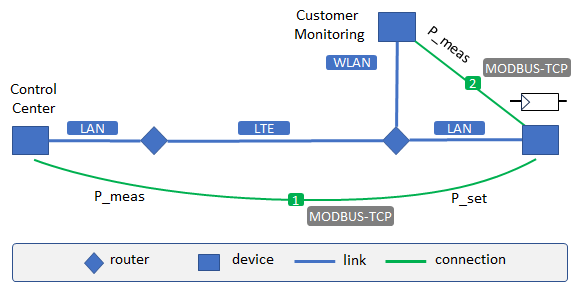

The physical model comprises three devices: a grid operator control center, a customer monitoring, and a PV plant. They are connected over two nodes using LAN, LTE and WLAN linktypes. The intended use case is the customer supervising the PV plant energy infeed, and the control center derating the PV plant power output in case of a grid congestion. Hence, there are two connections on the logical layer, both using MODBUS-TCP protocol. Connection 1 can be modeled as follows: 

In [ ]:
# Connection 1
from       = <Control center id>
to         = <PV controller id>
protocol   = "MODBUS-TCP"
info_items = [REQUEST, ACK]
peers      = [<Control center id>, <PV controller id>]
producer   = [0, 1]

The elements of the producer list here correspond to the elements of info_items. The values of each producer element can only be 0 or 1 and are meant as indices for the peers list. I.e. they point to the peer that is producing the information item. This means that the REQUEST information item is produced by peers[0], which is the Control center. The REQUEST is meant to request power deration. PV plant acknowledges the deration with an ACK - produced by peers [1] which is the PV controller. Also note that the from->to elements are always defined in "downstream" direction. Connection 2 can be modeled likewise:

In [ ]:
# Connection 2
from       = <PV controller id>
to         = <Customer monitoring id>
protocol   = "MODBUS-TCP"
info_items = [REQUEST, VALUE]
peers      = [<Customer monitoring id>, <PV controller id>]
producer   = [0, 1]

Meaning that the customer monitoring generates a request for obtaining the energy value, and the PV controller answers with that value. 

## Example with converter

The following graphic shows an extension of the simple example with usage of protocol converters. This time the customer operates an energy management system (EMS) which may also provide a power curtailment setpoint to the PV controller. Furthermore the PV controller uses a different physical link: RS485.

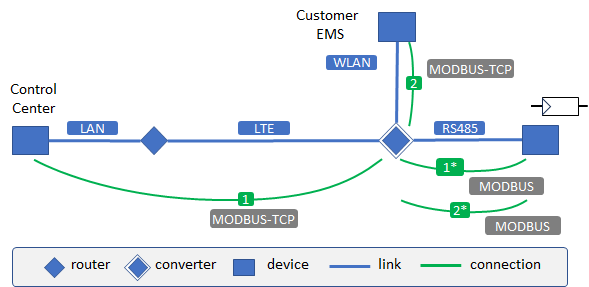

Although the controller still uses the MODBUS protocol, it is now mapped to RS485 which is non-TCP. Thus, one of the nodes is replaced by a converter. Note how introduction of the converter is modeled by creating additional connections. The control center deration is now communicated to the PV controller over connections (1) and (1*). These can be defined as follows: 

In [ ]:
# Connection 1										            
from       = <Control center id>					           
to         = <Converter id>							           
protocol   = "MODBUS-TCP"							           
info_items = [REQUEST, ACK]							           
peers      = [<Control center id>, <PV controller id>]           
producer   = [0, 1]									

# Connection 1*                                         
from       = <Converter id>                             
to         = <PV controller id>                         
protocol   = "MODBUS"                                   
info_items = [REQUEST, ACK]                             
peers      = [<Control center id>, <PV controller id>]  
producer   = [0, 1]                   

Again, from and to elements are defined in downstream direction. 
Connections (2) and (2*) handle the communication between EMS and the PV controller. They look similar but the control center is replaced by the EMS; also, the PV controller might answer with an energy VALUE or an ACK:

In [ ]:
# Connection 2                                     	                   
from       = <Customer EMS id>						                  
to         = <Converter id>							                  
protocol   = "MODBUS-TCP"							                  
info_items = [REQUEST, VALUE, ACK]					                  
peers      = [<Customer EMS id>, <PV controller id>]                  
producer   = [0, 1, 1]								

# Connection 2*                                  
from       = <Converter id>                      
to         = <PV controller id>                  
protocol   = "MODBUS"                            
info_items = [REQUEST, VALUE, ACK]               
peers      = [<Converter id>, <PV controller id>]
producer   = [0, 1, 1]     

The PV controller is understood to be at the downstream side again. Both info_items and producer lists now have three entries, in case of Connection 2* indicating that the Customer EMS produces a REQUEST for power deration, while the PV controller produces both VALUE (for energy) and ACK (to acknowledge the power deration) information elements. 